# 5 MWp Solar PV Plant — Python Design & Simulation
**Author:** Maduakor Uchechukwu David · MSc Energy for Solar Buildings and Cities

This notebook re-builds my 5 MWp Montpellier plant design in Python, step by step:

| # | Section | What it shows |
|---|---|---|
| 1 | Solar resource | Hourly weather from PVGIS, monthly irradiation, a day × hour heatmap |
| 2 | String sizing | Cold-weather Voc, hot Vmp and MPPT current checked against the inverter datasheet |
| 3 | Plane-of-array & cell temperature | Transposition to a 35° south-facing plane, SAPM cell temperature |
| 4 | Energy simulation | PVWatts DC + inverter model with clipping, monthly energy, PR, comparison with PVGIS |
| 5 | DC/AC ratio study | Energy gained vs clipping lost as the DC/AC ratio changes |
| 6 | Tilt & azimuth study | Annual in-plane irradiation for every tilt/azimuth pair |



**Libraries:** `pvlib`, `pandas`, `numpy`, `matplotlib`.  Install once with `pip install pvlib pandas matplotlib`.

In [ ]:
%pip install pvlib scikit-learn

In [14]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from pathlib import Path

plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "font.size": 10,
})
BLUE, ORANGE, GREY = "#2F6FB3", "#C2410C", "#8A8A8A"

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
print("pvlib", pvlib.__version__, "| pandas", pd.__version__)

pvlib 0.16.1 | pandas 2.2.3


**Libraries used**
- `pvlib`: downloads PVGIS weather and models solar position, irradiance and PV output
- `pandas`: stores the 8,760 hourly values in a table (DataFrame) with a time index
- `numpy`: fast maths on arrays (pandas is built on it)
- `matplotlib.pyplot`: plots and charts

## 1. Solar resource — Montpellier, France
PVGIS gives a **Typical Meteorological Year (TMY)**: 8,760 hourly values of irradiance (GHI, DNI, DHI), air temperature and wind speed.
Each month is picked as the most "typical" month from many real years of satellite data.
`pvlib.iotools.get_pvgis_tmy` downloads it directly. Timestamps are in **UTC**, and the year 1990 is only a placeholder.

In [3]:
weather,meta = pvlib.iotools.get_pvgis_tmy(latitude=43.611, longitude=3.877, map_variables=True)
weather.head()

,temp_air,relative_humidity,ghi,dni,dhi,IR(h),wind_speed,wind_direction,pressure
time(UTC),,,,,,,,,
1990-01-01 00:00:00+00:00,13.23,78.47,0.0,0.0,0.0,330.12,4.84,286.0,101500.0
1990-01-01 01:00:00+00:00,13.13,79.13,0.0,0.0,0.0,329.50,4.73,288.0,101480.0
1990-01-01 02:00:00+00:00,13.03,79.80,0.0,0.0,0.0,328.87,4.61,290.0,101500.0
1990-01-01 03:00:00+00:00,12.93,80.46,0.0,0.0,0.0,328.24,4.50,289.0,101490.0
1990-01-01 04:00:00+00:00,12.83,81.13,0.0,0.0,0.0,327.62,4.39,288.0,101480.0


In [15]:
# Statistics for the 5 key weather variables (real PVGIS TMY data)
cols = ["ghi", "dni", "dhi", "temp_air", "wind_speed"]

stats = weather[cols].describe().round(1)
stats

,ghi,dni,dhi,temp_air,wind_speed
count,8760.0,8760.0,8760.0,8760.0,8760.0
mean,185.9,224.8,63.2,15.2,3.6
std,268.0,318.5,87.2,7.3,1.8
min,0.0,0.0,0.0,-5.0,0.0
25%,0.0,0.0,0.0,10.3,2.2
50%,0.0,0.0,0.0,14.7,3.3
75%,329.0,518.4,117.0,20.4,4.6
max,977.0,988.5,462.0,40.6,11.8


**Data check:** `count` = 8,760 for every column, so no hours are missing.
The median GHI is 0 because about half of the hours are at night.
Peak GHI is 977 W/m², close to the 1,000 W/m² used at STC (Standard Test Conditions).
Air temperature ranges from −5 to 40.6 °C (mean 15.2 °C), and the mean wind speed is 3.6 m/s. Both are used later for cell temperature.

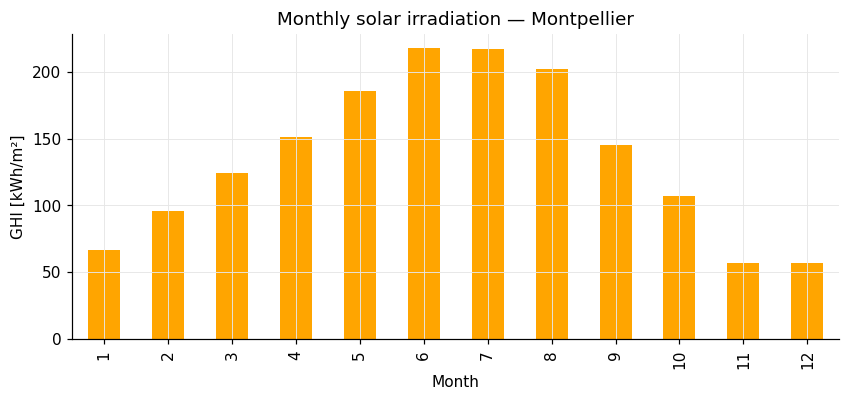

Annual GHI in Montpellier: 1628 kWh/m²


In [18]:
import matplotlib.pyplot as plt

monthly_ghi = weather["ghi"].groupby(weather.index.month).sum() / 1000

monthly_ghi.plot(kind="bar", color="orange")
plt.xlabel("Month")
plt.ylabel("GHI [kWh/m²]")
plt.title("Monthly solar irradiation — Montpellier")
plt.show()

annual_ghi = monthly_ghi.sum()
print(f"Annual GHI in Montpellier: {annual_ghi:.0f} kWh/m²")

**Result:** annual GHI = **1,628 kWh/m²**.
June–July give about 218 kWh/m² each, while Nov–Dec give about 57, roughly 4× less.
Production will therefore be strongly seasonal, peaking in summer.

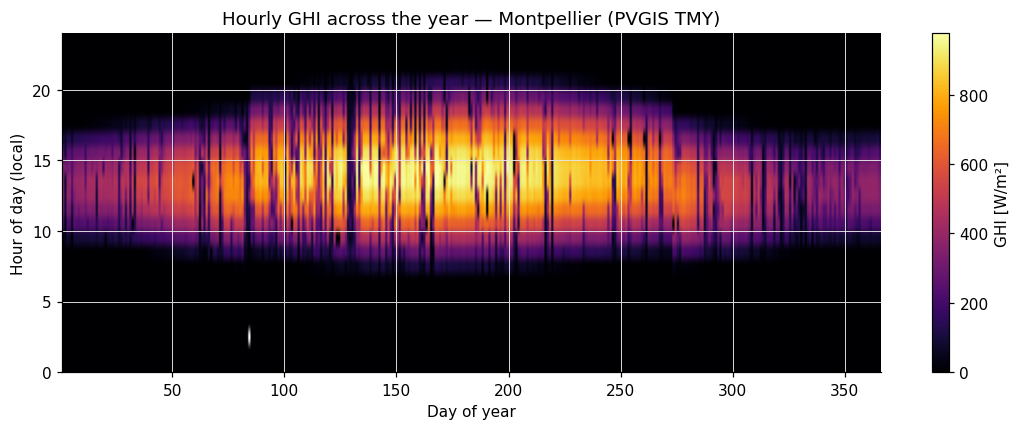

In [17]:
# Day-of-year × hour heatmap: where the solar energy sits in the year
weather = weather.tz_convert("Europe/Paris")
ghi_map = weather.pivot_table(
    index=weather.index.hour,         # rows = hour of day (0–23)
    columns=weather.index.dayofyear,  # columns = day of year (1–365)
    values="ghi"
)

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(ghi_map, aspect="auto", origin="lower",
               cmap="inferno", extent=[1, 366, 0, 24])
fig.colorbar(im, ax=ax, label="GHI [W/m²]")

ax.set_xlabel("Day of year")
ax.set_ylabel("Hour of day (local)")
ax.set_title("Hourly GHI across the year — Montpellier (PVGIS TMY)")
plt.show()

**Interpretation:** the bright band is the daylight period. It is wide in summer (long days) and narrow in winter.
The vertical dark streaks are cloudy days. This is real data, not a clear-sky model.
The band moves up by 1 h around day 87 and back around day 300: this is the summer-time clock change (local time).
The small white mark near day 85 at 2 am is the hour that does not exist when the clocks go forward (no data).